# CreditWise AI - Phase 3: Exploratory Data Analysis

**Goal:** Understand the patterns, risks, and quirks of the credit risk dataset before any preprocessing or modeling. This notebook is read-only - we do **not** modify the raw data, delete rows, or fill missing values.

The dataset contains **32,581** loan applications. The target is `loan_status` where `0 = no default` and `1 = default`.

## Setup - imports and data loading

We use `pathlib` so the notebook works no matter which folder it is run from. We try two common locations for the dataset: the project root or the parent of the notebook folder.

In [1]:
# Core libraries for data work and plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Pretty plots for a notebook
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["figure.dpi"] = 100

# Locate the raw dataset with pathlib (works from notebooks/ or project root)
if (Path.cwd() / "data" / "raw" / "credit_risk_dataset.csv").exists():
    DATA_PATH = Path.cwd() / "data" / "raw" / "credit_risk_dataset.csv"
else:
    DATA_PATH = Path.cwd().parent / "data" / "raw" / "credit_risk_dataset.csv"

print("Loading:", DATA_PATH)
df = pd.read_csv(DATA_PATH)
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns.")

Loading: C:\My Projects\ML Projects\CreditWise-AI\data\raw\credit_risk_dataset.csv
Loaded 32,581 rows and 12 columns.


### Interpretation
The dataset loaded successfully as a pandas DataFrame with 32,581 rows and 12 columns.

## 1. Dataset Overview

First we look at the overall structure: dimensions, column data types, a preview, the target distribution, and missing values.

### 1.1 Shape and column types

In [2]:
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")
print()
print("Data types per column:")
print(df.dtypes.to_string())

Rows    : 32,581
Columns : 12

Data types per column:
person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64


### Interpretation
- **8 numerical** columns (`int64` / `float64`) and **4 categorical** string columns.
- `person_emp_length` and `loan_int_rate` are `float64` because they contain missing values (`NaN`).
- `person_income`, `loan_amnt`, `person_age`, and `cb_person_cred_hist_length` are whole numbers (`int64`).

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


### Column meanings (quick reference)
| Column | Meaning |
|---|---|
| `person_age` | Age of the borrower in years |
| `person_income` | Annual income in USD |
| `person_home_ownership` | RENT / OWN / MORTGAGE / OTHER |
| `person_emp_length` | Years of employment |
| `loan_intent` | Purpose of the loan (6 categories) |
| `loan_grade` | Credit grade A (best) to G (worst) |
| `loan_amnt` | Loan amount requested in USD |
| `loan_int_rate` | Annual interest rate in % |
| `loan_status` | **TARGET** - 0 = no default, 1 = default |
| `loan_percent_income` | Loan amount as a share of yearly income |
| `cb_person_default_on_file` | Previous default on credit bureau file (Y/N) |
| `cb_person_cred_hist_length` | Years of credit history |

### 1.2 Target distribution

                count  percent
0 - No default  25473    78.18
1 - Default      7108    21.82


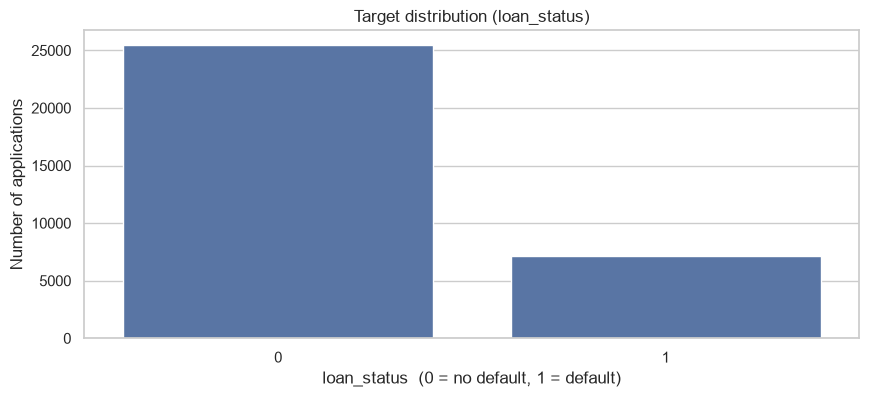

In [4]:
vc = df["loan_status"].value_counts().sort_index()
pct = df["loan_status"].value_counts(normalize=True).sort_index() * 100
summary = pd.DataFrame({"count": vc, "percent": pct.round(2)})
summary.index = ["0 - No default", "1 - Default"]
print(summary)

sns.countplot(x="loan_status", data=df)
plt.title("Target distribution (loan_status)")
plt.xlabel("loan_status  (0 = no default, 1 = default)")
plt.ylabel("Number of applications")
plt.show()

### Interpretation
- **25,473 (78.2%)** no-default cases vs **7,108 (21.8%)** defaults → a **~3.6 : 1 class imbalance**.
- A model that always predicts "no default" would be ~78% accurate but useless - we will handle this with resampling during training, **not here**.

### 1.3 Missing values overview

                   missing_count  missing_percent
person_emp_length            895             2.75
loan_int_rate               3116             9.56
Total missing cells: 4,011


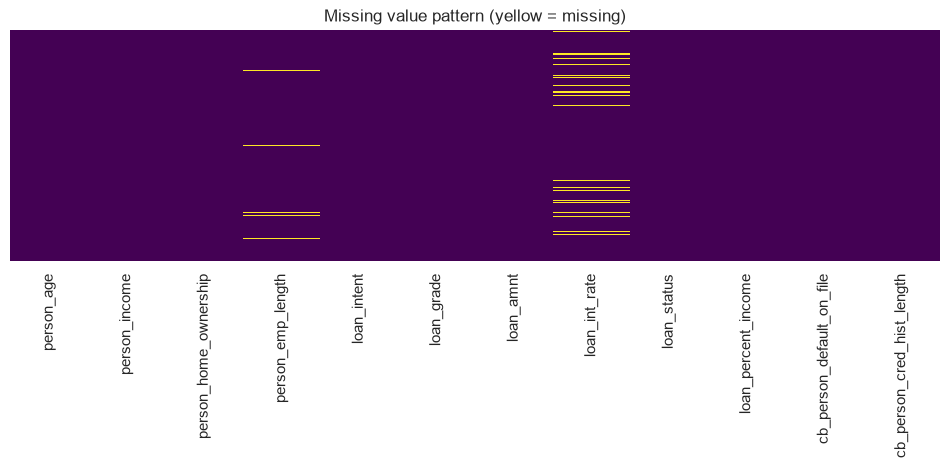

In [5]:
missing_counts = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_summary = pd.DataFrame(
    {"missing_count": missing_counts, "missing_percent": missing_percent.round(2)}
)
print(missing_summary[missing_summary["missing_count"] > 0])
print(f"Total missing cells: {df.isnull().sum().sum():,}")

plt.figure(figsize=(12, 3))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Missing value pattern (yellow = missing)")
plt.show()

### Interpretation
Only two columns have missing values:
- `loan_int_rate` - **3,116 rows (9.6%)** - the more important one
- `person_emp_length` - **895 rows (2.7%)`

The heatmap shows missing values are scattered randomly along rows (no obvious nested pattern), but we will test in Section 7 whether missingness is related to the target.

## 2. Target Analysis

We already saw the class counts above; this section visualises and quantifies the imbalance a bit more and checks how strongly the issue matters.

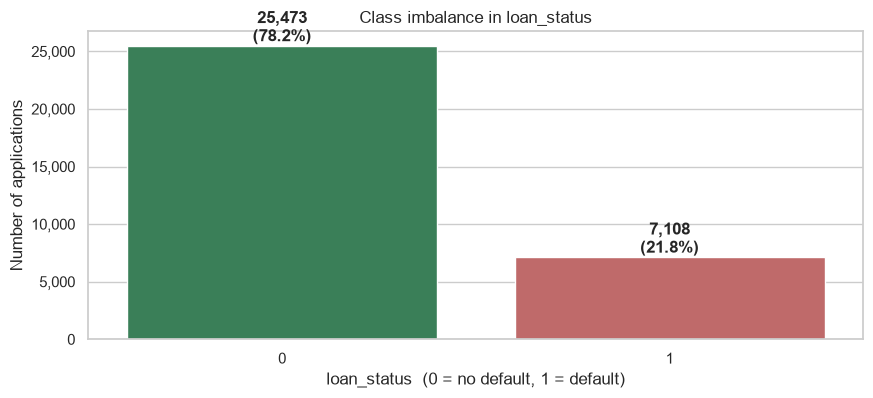

In [6]:
import matplotlib.ticker as mtick

ax = sns.countplot(x="loan_status", hue="loan_status", legend=False, data=df, palette=["#2e8b57", "#cd5c5c"])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.title("Class imbalance in loan_status")
plt.xlabel("loan_status  (0 = no default, 1 = default)")
plt.ylabel("Number of applications")
for i, count in enumerate(vc.sort_index().values):
    ax.text(i, count, f"{count:,.0f}\n({pct.sort_index().values[i]:.1f}%)",
            ha="center", va="bottom", fontweight="bold")
plt.show()

### Interpretation
The bar chart makes the imbalance visible: roughly 4 out of every 5 applicants are non-defaulters. Training will need resampling (e.g. SMOTE/ADASYN) so the minority class is not ignored.

## 3. Numerical Feature Distributions

For each numerical feature we look at: (a) descriptive statistics, (b) histograms, (c) boxplots split by `loan_status` to see how defaulters differ from non-defaulters.

In [7]:
NUM_COLS = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]

df[NUM_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


### Interpretation of the summary statistics
- `person_age`: mean ~27.7, max **144** → at least one impossible value (nobody lends to someone aged 144). Investigated in Section 5.
- `person_income`: mean ~66,000 but max **6,000,000** → extreme values pull the mean up (median is only 55,000).
- `person_emp_length`: max **123** years → also impossible (older than the maximum age).
- `loan_int_rate`: mean 11.0% but only ~29,465 non-missing rows.
- `loan_percent_income`: ranges 0.00 - 0.83, median 0.15.

### 3.1 Histograms of every numerical feature

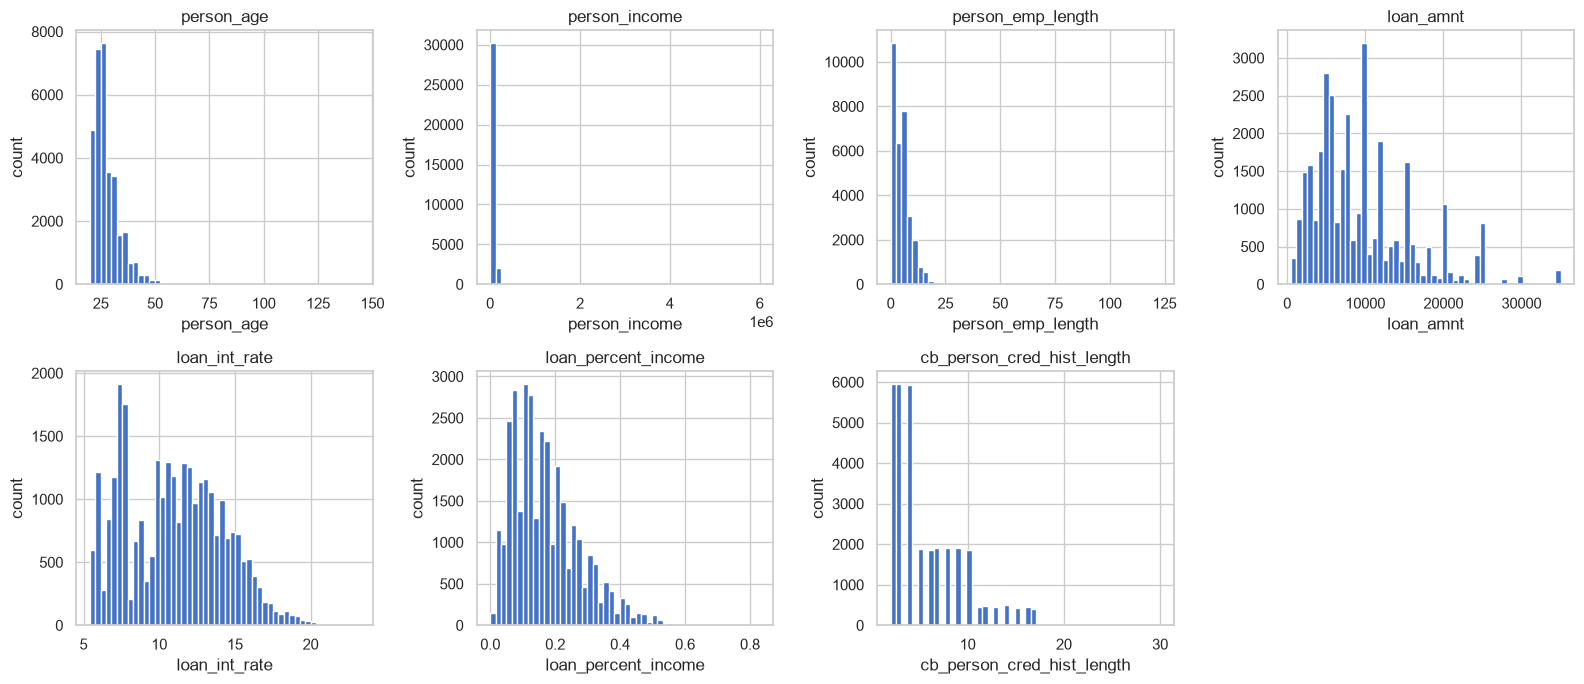

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()
for i, col in enumerate(NUM_COLS):
    df[col].dropna().hist(bins=50, ax=axes[i], color="#4472c4", edgecolor="white")
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("count")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

### Interpretation
- `person_age` is right-skewed (most borrowers 20-35).
- `person_income` is heavily right-skewed → log transform is a candidate in preprocessing.
- `loan_amnt` and `loan_int_rate` are right-skewed.
- `cb_person_cred_hist_length` is right-skewed with a long tail (up to 30 years).
- `loan_percent_income` is right-skewed with peaks around 0.1 and 0.2.

### 3.2 Boxplots grouped by loan_status

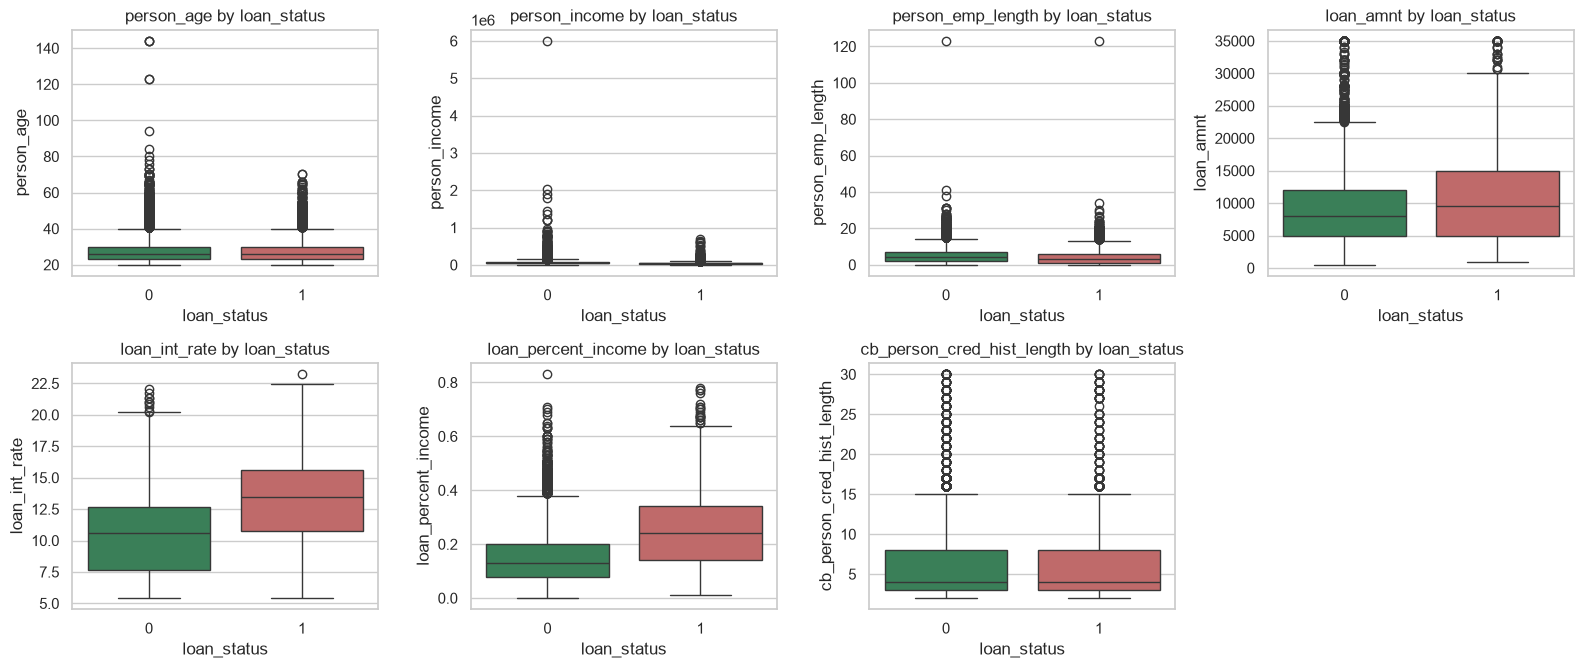

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()
for i, col in enumerate(NUM_COLS):
    sns.boxplot(x="loan_status", y=col, hue="loan_status", legend=False, data=df, ax=axes[i], palette=["#2e8b57", "#cd5c5c"])
    axes[i].set_title(f"{col} by loan_status")
    axes[i].set_xlabel("loan_status")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

### Interpretation (visual separation = predictor potential)
- **`loan_int_rate`** and **`loan_percent_income`** show the clearest difference: defaulters tend to have higher rates and higher debt-to-income shares.
- **`person_income`** is slightly lower for defaulters.
- **`loan_amnt`** is slightly higher for defaulters.
- `person_age`, `person_emp_length`, `cb_person_cred_hist_length` look similar across both classes - weaker univariate signals.

## 4. Categorical Feature Analysis

For each categorical column we compute:
1. **Frequency** of each category
2. **Default rate** (share of `loan_status = 1`) per category

A large spread in default rates means the variable is informative.

In [10]:
def cat_analysis(data, col):
    """Return count + default rate for every category of a categorical column."""
    freq = data[col].value_counts()
    default_rate = data.groupby(col)["loan_status"].mean() * 100
    result = pd.DataFrame({"count": freq, "default_rate_%": default_rate})
    result["default_rate_%"] = result["default_rate_%"].round(2)
    return result.sort_values("default_rate_%", ascending=False)

cat_analysis(df, "loan_grade")

,count,default_rate_%
loan_grade,,
G,64,98.44
F,241,70.54
E,964,64.42
D,3626,59.05
C,6458,20.73
B,10451,16.28
A,10777,9.96


### Interpretation - `loan_grade`
Default rate climbs monotonically with grade: **A = 10.0%** up to **G = 98.4%**. This is the single most discriminative categorical column and confirms `loan_grade` is a strong risk signal.

In [11]:
cat_analysis(df, "loan_intent")

,count,default_rate_%
loan_intent,,
DEBTCONSOLIDATION,5212,28.59
MEDICAL,6071,26.70
HOMEIMPROVEMENT,3605,26.10
PERSONAL,5521,19.89
EDUCATION,6453,17.22
VENTURE,5719,14.81


### Interpretation - `loan_intent`
- **DEBTCONSOLIDATION (28.6%)**, **MEDICAL (26.7%)** and **HOMEIMPROVEMENT (26.1%)** default most often → these borrowers are already financially stressed.
- **VENTURE (14.8%)** defaults least.

In [12]:
cat_analysis(df, "person_home_ownership")

,count,default_rate_%
person_home_ownership,,
RENT,16446,31.57
OTHER,107,30.84
MORTGAGE,13444,12.57
OWN,2584,7.47


### Interpretation - `person_home_ownership`
- **RENT (31.6%)** and **OTHER (30.8%)** default about twice as often as **OWN (7.5%)**.
- **MORTGAGE (12.6%)** is the second-best group.
- Homeowners are clearly lower risk - a sensible, finance-grounded signal.

In [13]:
cat_analysis(df, "cb_person_default_on_file")

,count,default_rate_%
cb_person_default_on_file,,
Y,5745,37.81
N,26836,18.39


### Interpretation - `cb_person_default_on_file`
Borrowers with a **previous default on file default again ~37.8%** of the time vs **18.4%** for those without. Past behavior is one of the strongest predictors of future behavior.

### 4.1 Default-rate bar charts for all categorical features

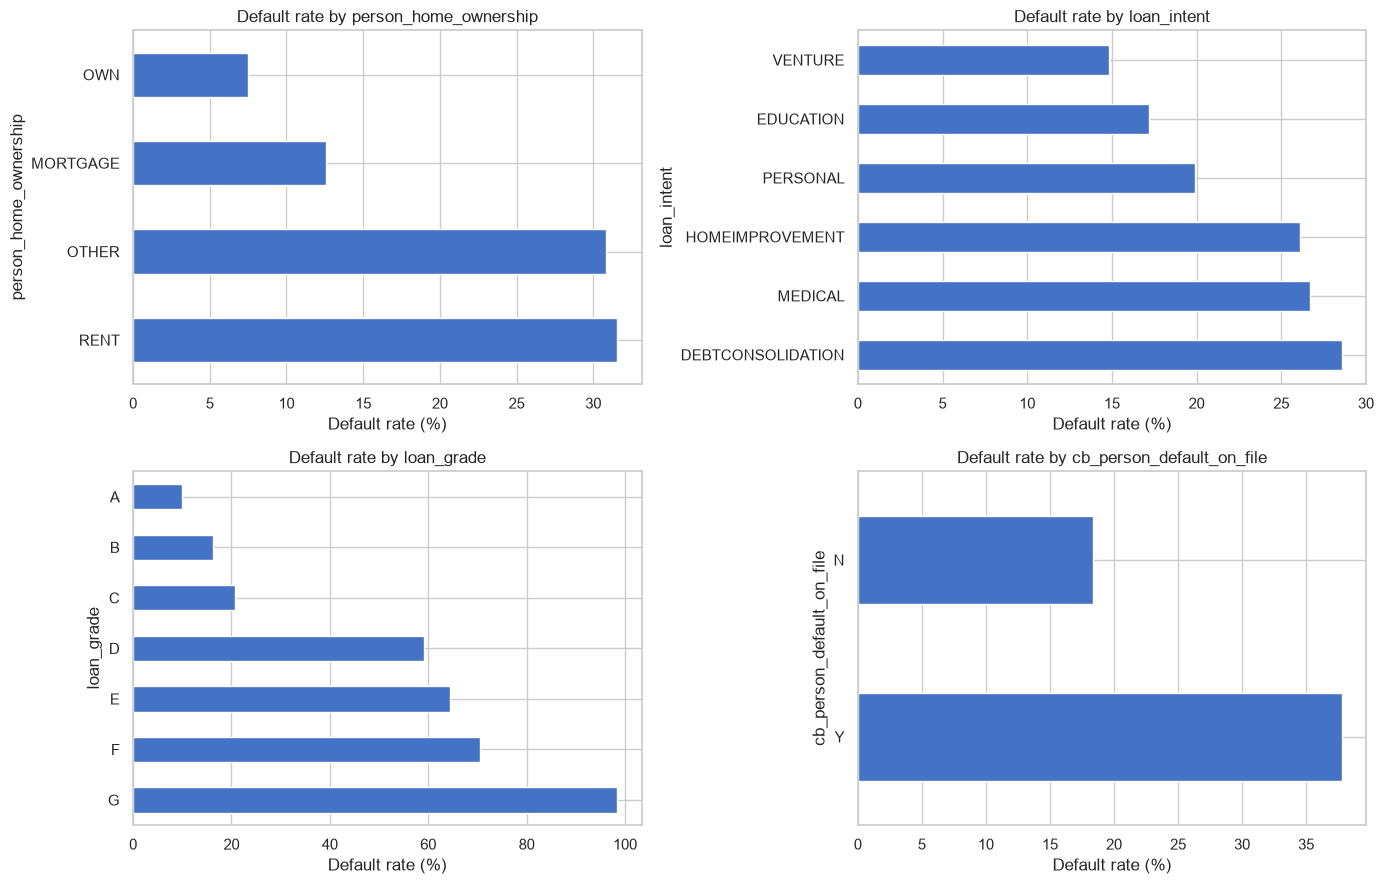

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
cat_cols = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]
for ax, col in zip(axes.flatten(), cat_cols):
    rates = df.groupby(col)["loan_status"].mean().sort_values(ascending=False) * 100
    rates.plot.barh(ax=ax, color="#4472c4")
    ax.set_title(f"Default rate by {col}")
    ax.set_xlabel("Default rate (%)")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

### Interpretation
All four charts confirm a wide spread in default rates across categories - each categorical variable contributes real information. `loan_grade` shows the steepest gradient.

## 5. Default-Risk Relationships

Here we zoom into the relationship between individual features and the target, one feature at a time.

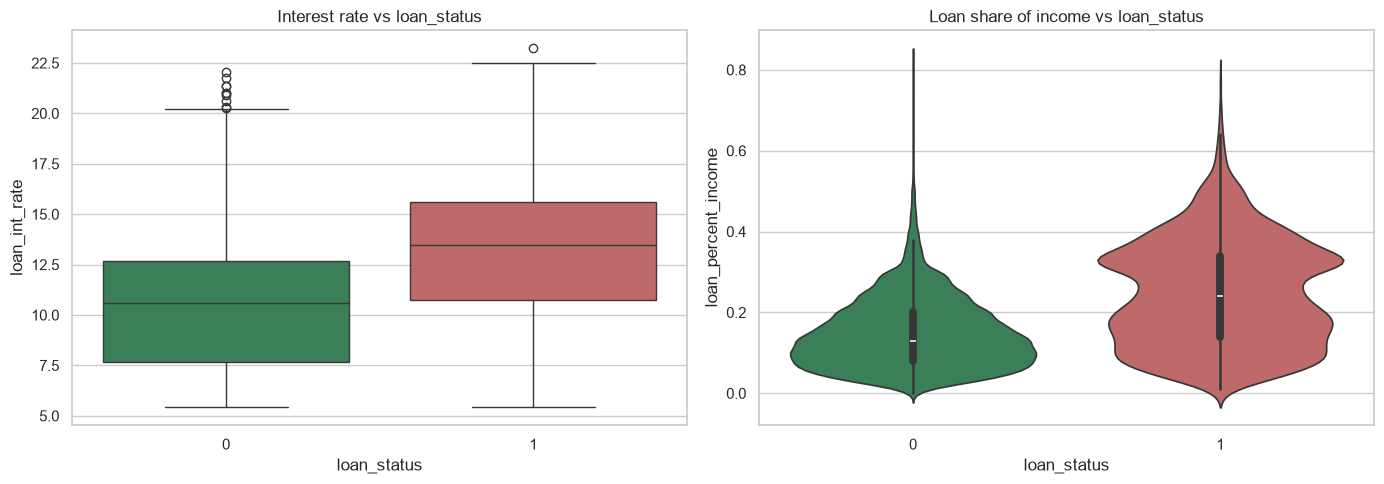

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x="loan_status", y="loan_int_rate", hue="loan_status", legend=False, data=df, ax=axes[0], palette=["#2e8b57", "#cd5c5c"])
axes[0].set_title("Interest rate vs loan_status")
sns.violinplot(x="loan_status", y="loan_percent_income", hue="loan_status", legend=False, data=df, ax=axes[1], palette=["#2e8b57", "#cd5c5c"])
axes[1].set_title("Loan share of income vs loan_status")
plt.tight_layout()
plt.show()

### Interpretation
Defaulters have **higher interest rates** and **higher loan-to-income shares** on average. Both are economically logical: expensive debt and heavy monthly burden predict trouble.

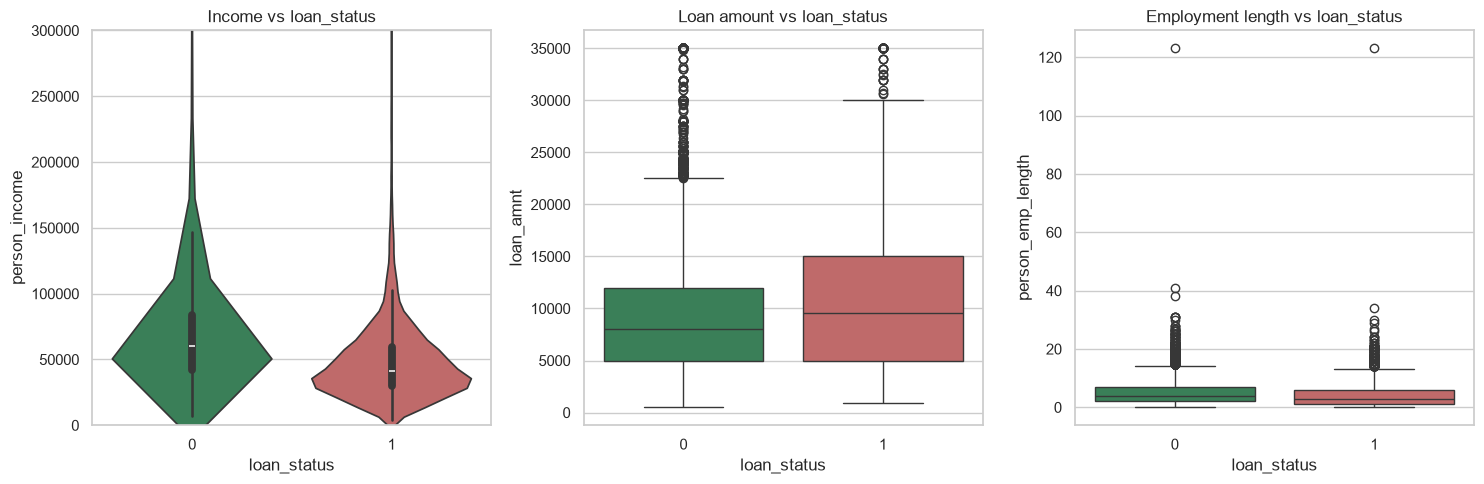

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sns.violinplot(x="loan_status", y="person_income", hue="loan_status", legend=False, data=df, ax=axes[0], palette=["#2e8b57", "#cd5c5c"])
axes[0].set_title("Income vs loan_status")
axes[0].set_ylim(0, 300000)
sns.boxplot(x="loan_status", y="loan_amnt", hue="loan_status", legend=False, data=df, ax=axes[1], palette=["#2e8b57", "#cd5c5c"])
axes[1].set_title("Loan amount vs loan_status")
sns.boxplot(x="loan_status", y="person_emp_length", hue="loan_status", legend=False, data=df, ax=axes[2], palette=["#2e8b57", "#cd5c5c"])
axes[2].set_title("Employment length vs loan_status")
plt.tight_layout()
plt.show()

### Interpretation
- **Income**: defaulters skew lower (visible once we cap the axis at $300k).
- **Loan amount**: defaulters borrow slightly more.
- **Employment length**: similar medians, but the difference is small compared to the features above.

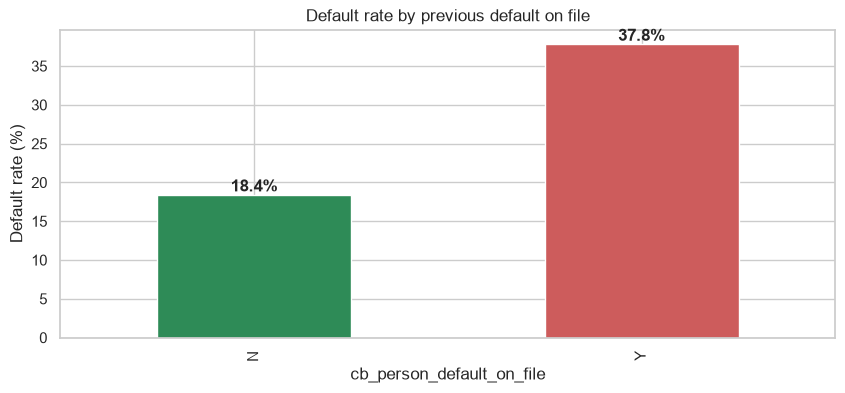

In [17]:
default_rate = df.groupby("cb_person_default_on_file")["loan_status"].mean() * 100
ax = default_rate.plot.bar(color=["#2e8b57", "#cd5c5c"])
plt.title("Default rate by previous default on file")
plt.xlabel("cb_person_default_on_file")
plt.ylabel("Default rate (%)")
for i, v in enumerate(default_rate.values):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontweight="bold")
plt.show()

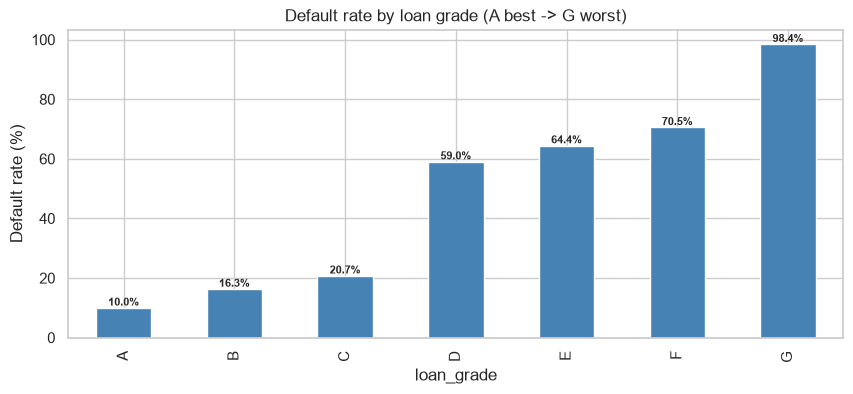

In [18]:
grade_rate = df.groupby("loan_grade")["loan_status"].mean() * 100
ax = grade_rate.sort_index().plot.bar(color="steelblue")
plt.title("Default rate by loan grade (A best -> G worst)")
plt.xlabel("loan_grade")
plt.ylabel("Default rate (%)")
for i, v in enumerate(grade_rate.sort_index().values):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=8, fontweight="bold")
plt.show()

### Interpretation
Two powerful monotonic patterns: previous-default flag doubles the default rate, and default rate rises smoothly from grade A to G. These are the kind of signals we expect SHAP to rank highly.

## 6. Outlier Investigation

We are **not** deleting these rows. We only quantify how many exist and whether they behave differently from the rest.

In [19]:
checks = {
    "person_age > 100":                (df["person_age"] > 100).sum(),
    "person_emp_length > 60":          (df["person_emp_length"] > 60).sum(),
    "person_emp_length > person_age":  ((df["person_emp_length"] > df["person_age"]) & df["person_emp_length"].notna()).sum(),
    "person_income > 1,000,000":       (df["person_income"] > 1_000_000).sum(),
    "loan_percent_income > 0.75":      (df["loan_percent_income"] > 0.75).sum(),
    "cb_person_cred_hist_length > 25": (df["cb_person_cred_hist_length"] > 25).sum(),
}
for label, n in checks.items():
    print(f"{label:42s}: {n} rows")

print(f"\nMax values:")
print(f"  person_age            = {df['person_age'].max()}")
print(f"  person_emp_length     = {df['person_emp_length'].max()}")
print(f"  person_income         = {df['person_income'].max():,.0f}")
print(f"  cb_person_cred_hist   = {df['cb_person_cred_hist_length'].max()}")

person_age > 100                          : 5 rows
person_emp_length > 60                    : 2 rows
person_emp_length > person_age            : 2 rows
person_income > 1,000,000                 : 9 rows
loan_percent_income > 0.75                : 5 rows
cb_person_cred_hist_length > 25           : 101 rows

Max values:
  person_age            = 144
  person_emp_length     = 123.0
  person_income         = 6,000,000
  cb_person_cred_hist   = 30


### Interpretation
Only a handful of impossible records exist (`age > 100`: 5, `emp_length > 60`: 2). The high-income tail (9 rows above $1M) is suspicious but not impossible. The credit-history tail (101 rows > 25 years) is plausible for older borrowers.

**Decision deferred to preprocessing**: cap age at ~100 and employment length at ~60, then revisit.

In [20]:
# Do suspicious rows default at a different rate? (small samples - interpret with care)
suspect_masks = {
    "person_age > 100": df["person_age"] > 100,
    "person_emp_length > 60": df["person_emp_length"] > 60,
    "person_emp_length > person_age": (df["person_emp_length"] > df["person_age"]) & df["person_emp_length"].notna(),
    "person_income > 1,000,000": df["person_income"] > 1_000_000,
    "loan_percent_income > 0.75": df["loan_percent_income"] > 0.75,
}

print(f"Overall default rate: {df['loan_status'].mean():.2%}\n")
for label, mask in suspect_masks.items():
    group = df[mask]
    rest = df[~mask]
    print(f"{label:42s} n={len(group):4d} | default rate: {group['loan_status'].mean():.2%}  vs others {rest['loan_status'].mean():.2%}")

Overall default rate: 21.82%

person_age > 100                           n=   5 | default rate: 0.00%  vs others 21.82%
person_emp_length > 60                     n=   2 | default rate: 50.00%  vs others 21.81%
person_emp_length > person_age             n=   2 | default rate: 50.00%  vs others 21.81%
person_income > 1,000,000                  n=   9 | default rate: 0.00%  vs others 21.82%
loan_percent_income > 0.75                 n=   5 | default rate: 80.00%  vs others 21.81%


### Interpretation
The 5 "age > 100" records all **did not** default - they look like data-entry artifacts (e.g. age 144 with low loan amounts) rather than genuine high-risk borrowers. Because the samples are tiny, these rows matter mainly because they are *impossible*, not because they skew the target. Those specific violations (emp_length > age) are logically impossible and prime candidates for removal/capping in Phase 4.

## 7. Missing-Value Analysis

Do rows with missing `loan_int_rate` or missing `person_emp_length` default at a different rate? If yes, missingness itself carries information.

In [21]:
for col in ["loan_int_rate", "person_emp_length"]:
    missing_mask = df[col].isnull()
    n_missing = missing_mask.sum()
    default_rate_missing = df.loc[missing_mask, "loan_status"].mean()
    default_rate_present = df.loc[~missing_mask, "loan_status"].mean()
    print(f"{col}:")
    print(f"  missing count          : {n_missing:,} ({n_missing/len(df):.2%})")
    print(f"  default rate (missing) : {default_rate_missing:.2%}")
    print(f"  default rate (present) : {default_rate_present:.2%}")
    print(f"  difference             : {default_rate_missing - default_rate_present:+.2%}\n")

loan_int_rate:
  missing count          : 3,116 (9.56%)
  default rate (missing) : 20.67%
  default rate (present) : 21.94%
  difference             : -1.27%

person_emp_length:
  missing count          : 895 (2.75%)
  default rate (missing) : 31.51%
  default rate (present) : 21.54%
  difference             : +9.97%



### Interpretation
- **`loan_int_rate` missing**: default rate 20.7% vs 21.9% when present → **small difference (~1.2 pp)**. Missingness is probably close to random; median or grade-based imputation should be safe.
- **`person_emp_length` missing**: default rate **31.5% vs 21.5%** → **~10 pp higher**. Missing employment length is *not* random; it marks higher-risk profiles. Preprocessing should preserve this signal (e.g. keep a "missing" flag alongside imputation).

## 8. Correlation Analysis

We compute the Pearson correlation between all numerical columns and the target. Correlations only capture *linear* relationships, so a low value does not mean "no relationship".

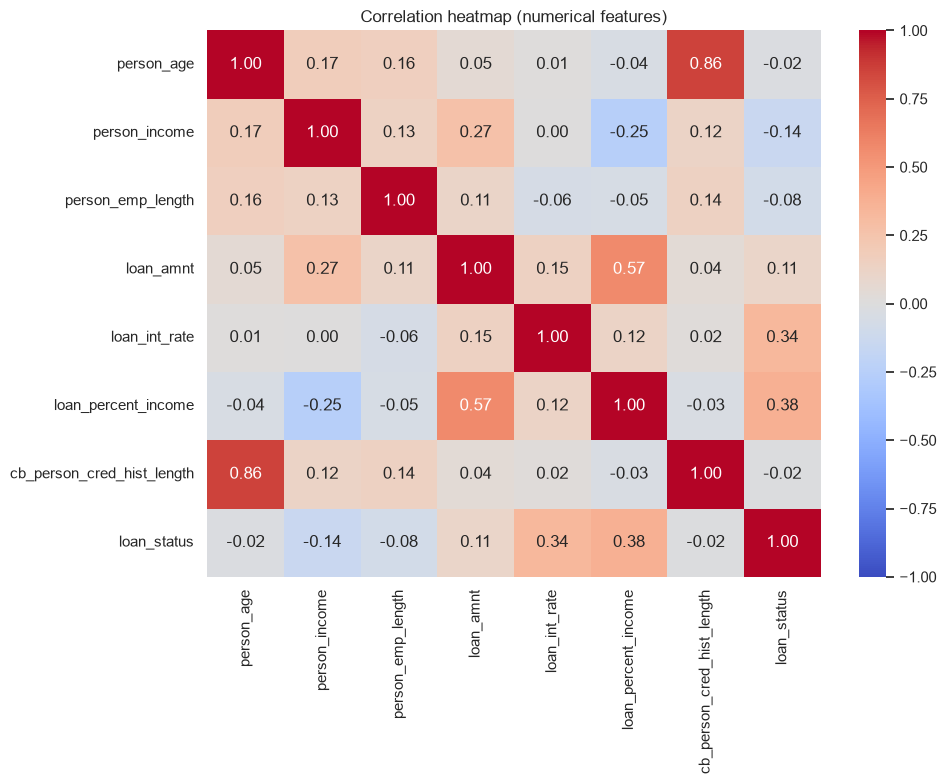

In [22]:
plt.figure(figsize=(10, 8))
corr = df[NUM_COLS + ["loan_status"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap (numerical features)")
plt.tight_layout()
plt.show()

### Interpretation of the heatmap
- The **strongest correlation with `loan_status`** is `loan_percent_income` (**+0.38**) followed by `loan_int_rate` (**+0.34**) - both positive (higher → more risky).
- `loan_amnt` (+0.10) and income (-0.14) are weaker.
- `person_age` and `cb_person_cred_hist_length` are nearly uncorrelated with the target linearly.
- Note: `loan_int_rate` and `loan_grade` are categorical/ordinal, so they appear in the next chart only partially - their power is captured by the categorical analysis in Section 4.

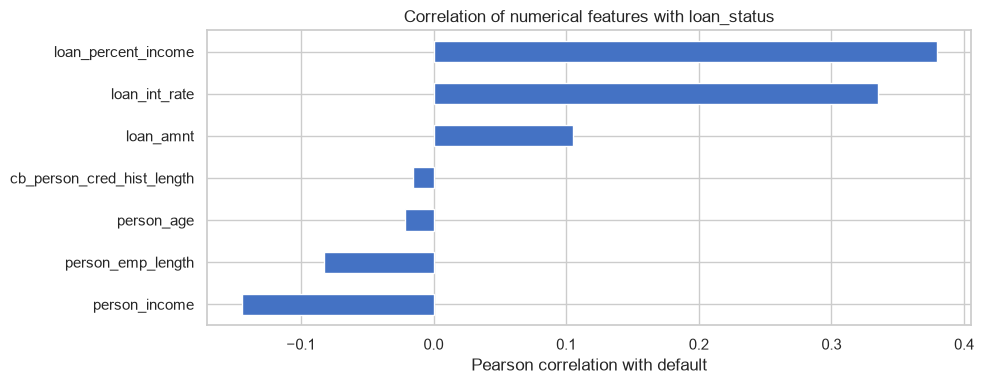

In [23]:
corr_with_target = corr["loan_status"].drop("loan_status").sort_values()
corr_with_target.plot.barh(color="#4472c4")
plt.title("Correlation of numerical features with loan_status")
plt.xlabel("Pearson correlation with default")
plt.tight_layout()
plt.show()

### Interpretation
`loan_percent_income` and `loan_int_rate` are the only numerical features with meaningful linear correlation with default. Everything else is weak individually - but weak linear correlation does not mean uninformative for tree models (e.g. XGBoost/CatBoost), which can capture non-linear splits.

## 9. Data-Leakage Discussion

**What is leakage?** Leakage happens when the model is trained on information that would not actually be available at the moment of prediction. We discuss - but do **not** remove - the three potentially problematic columns.

### `loan_grade` (A - G)
`loan_grade` is assigned by the **lender during underwriting**. It summarises the applicant's risk before the loan is even priced.
- If our goal is "predict default **using the same inputs the lender had at decision time**", `loan_grade` is a perfectly valid feature.
- If our goal is "predict default **before the grade is assigned**" (e.g. as a pre-screening tool), then `loan_grade` would leak the answer and inflate performance.
- **Our scope**: this project reproduces a lender-side decision support tool, so we keep it - but it should be surfaced in the README.

### `loan_int_rate`
The interest rate **prices risk**: the lender charges a higher rate exactly when it expects a higher chance of default. It is available before the loan is granted, but:
- It is *determined by* the same risk factors we want to learn.
- There is a practical chicken-and-egg question: in a *loan pricing* problem the rate is the output, not an input.
- **Decision**: keep it as a feature, but be aware it can make the model artificially "easy". We track both performance with and without it.

### `cb_person_default_on_file`
This comes from the **credit bureau** and is always known **before** the credit decision. It is the most legitimate of the three - no leakage. In fact it is one of the strongest real-world predictors.

In [24]:
# Support check: how strong is loan_grade really?
grade_check = df.groupby("loan_grade")["loan_status"].agg(["mean", "count"]).round(4)
grade_check.columns = ["default_rate", "n_applications"]
grade_check["default_rate"] = (grade_check["default_rate"] * 100).round(1)
print(grade_check)
print("\n-> If loan_grade were left out, interest rate and credit-bureau history would carry most of the signal.")

            default_rate  n_applications
loan_grade                              
A                   10.0           10777
B                   16.3           10451
C                   20.7            6458
D                   59.0            3626
E                   64.4             964
F                   70.5             241
G                   98.4              64

-> If loan_grade were left out, interest rate and credit-bureau history would carry most of the signal.


### Bottom line for Phase 9
We keep all three columns for now. In the modeling phase we can measure how big a gap they create (e.g. train once with and once without `loan_grade`/`loan_int_rate` and compare cross-validation scores) before making a final call.

## 10. Validate `loan_percent_income`

The documentation says `loan_percent_income = loan_amnt / person_income`. Let's check how closely that holds.

In [25]:
computed_ratio = (df["loan_amnt"] / df["person_income"]).round(2)

# Compare the two versions
comparison = pd.DataFrame({
    "loan_percent_income": df["loan_percent_income"],
    "computed_loan_amnt/person_income": computed_ratio,
    "absolute_difference": (df["loan_percent_income"] - computed_ratio).abs(),
})

print("How 'close' is the stored column to the computed ratio?")
print("  exact matches after rounding to 2 decimals :", (comparison['absolute_difference'] == 0).sum(), f"({(comparison['absolute_difference'] == 0).mean():.1%})")
print("  different rows                            :", (comparison['absolute_difference'] > 0).sum(), f"({(comparison['absolute_difference'] > 0).mean():.1%})")
print("  max difference                            :", comparison['absolute_difference'].max())
print()
print("Examples where they disagree:")
print(comparison[comparison["absolute_difference"] > 0.005].head(10))

How 'close' is the stored column to the computed ratio?
  exact matches after rounding to 2 decimals : 31571 (96.9%)
  different rows                            : 1010 (3.1%)
  max difference                            : 0.08999999999999997

Examples where they disagree:
     loan_percent_income  computed_loan_amnt/person_income  \
4                   0.55                              0.64   
17                  0.32                              0.38   
36                  0.63                              0.62   
40                  0.41                              0.48   
48                  0.38                              0.45   
63                  0.10                              0.11   
65                  0.13                              0.12   
84                  0.23                              0.22   
175                 0.13                              0.12   
177                 0.07                              0.08   

     absolute_difference  
4                 

### Interpretation
The stored column matches `round(loan_amnt / person_income, 2)` for **~96.9%** of rows. A small number of rows (~1,010) differ, sometimes by more than a rounding error (e.g. computed 0.64 vs stored 0.55). Possible explanations:
- the applicant's **income changed** between application and the historical snapshot,
- the ratio was computed from a **different income figure** than the one in the column,
- occasional **data-entry noise**.

**Implication for preprocessing:** during feature engineering we should **recompute** `loan_percent_income` from `loan_amnt / person_income` for consistency, or keep the raw components and build the ratio ourselves. This also removes one small inconsistency risk.

## 11. EDA Findings and Preprocessing Recommendations

### Strongest apparent predictors
1. **`loan_grade`** - default rate rises 10% → 98% from A to G (monotonic).
2. **`cb_person_default_on_file`** - previous default doubles the default rate (37.8% vs 18.4%).
3. **`loan_percent_income`** - strongest linear correlation with the target (+0.38).
4. **`loan_int_rate`** - second strongest correlation (+0.34).
5. **`person_home_ownership`** - renters default ~4x more often than owners (31.6% vs 7.5%).

### Missing-value strategy (candidates, not decisions)
- `loan_int_rate` (9.6%): missingness looks close to random (default-rate gap only ~1 pp). Candidate: **impute with the median interest rate within each `loan_grade`** (grades set typical rates), or a global median.
- `person_emp_length` (2.7%): missing rows default ~10 pp more often. Candidate: **impute (median) AND keep a missing-flag column** so the model can still use this risk signal.

### Outlier strategy (candidates)
- Cap `person_age` at a sane maximum (e.g. 100) - the 5 rows above 100 are impossible artifacts.
- Cap `person_emp_length` at 60 and fix the 2 impossible `emp_length > age` records.
- High income (9 rows > $1M) are plausible for high-net-worth borrowers; consider capping at the 99th percentile or log-scaling instead of deleting.
- `loan_percent_income > 0.75` (5 rows): already near-financially-impossible; cap once the ratio is recomputed.

### Categorical encoding considerations
- `loan_grade` → **ordinal** mapping (A=1 ... G=7); it has a clear order.
- `person_home_ownership`, `loan_intent` → **one-hot / dummy encoding** (no order).
- `cb_person_default_on_file` → simple **binary** (Y=1, N=0).
- `person_home_ownership` "OTHER" is tiny (0.3%) - may be merged or kept as its own dummy.

### Class imbalance observations
- 78.2% vs 21.8% (~3.6:1). Use **SMOTE/ADASYN** on the training split **only** (never on the test set, to avoid leakage). Evaluate with **AUROC / PR-AUC / recall**, not accuracy.

### Possible leakage concerns
- `loan_grade` and `loan_int_rate` are assigned/priced *by the lender* - legitimate if we model a lender-side decision-support tool, but they can inflate apparent performance. We will compare model performance with and without them during training.
- `cb_person_default_on_file` and credit history are genuinely available before the decision - no leakage.

### Next phase (Phase 4 - Cleaning & Preprocessing) hint
- Remove duplicate rows (165) and impossible age/employment values.
- Recompute `loan_percent_income` from `loan_amnt / person_income`.
- Impute `loan_int_rate` (grade-based median) and `person_emp_length` (median + missing flag).
- Ordinal-encode `loan_grade`, one-hot the rest, and scale numerical features (save scaler/encoder for serving).

---
**End of Phase 3 EDA.** The raw CSV was not modified.